# 02 · The Interpolation Peak

**Claim:** the worst model is not "too big". It is the model with *exactly* enough parameters to fit every training point ($p = n$). There, test error spikes, and the spike is made of noise.

*Double Descent 101 · notebook 2 of 6 · previous: [01 · The classical U](01_the_classical_u.ipynb) · next: [03 · The second descent](03_the_second_descent.ipynb)*

## Keep going past the sweet spot

Same two tracks as notebook 01 (1-D polynomials with $n = 15$, 20-D random ReLU features with $n = 100$), same minimum-norm least-squares fit. Now the capacity sweep runs up to and just beyond the **interpolation threshold** $p = n$, at four noise levels $\sigma \in \{0, 0.1, 0.3, 0.5\}$. Every noise level reuses the same inputs, noise draw and features, so the curves differ only by noise.

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, example_fits, factory_for, run_capacity_experiment, summarize_curve, task_for
from src.evaluation.comparison import MODEL_LABELS
from src.reporting import publish_figure, save_json
from src.theory.threshold import conditioning_sweep
from src.visualisation import (
    MODEL_COLORS, capacity_axes, format_error, new_figure, noise_colors, plot_curve, plot_fit,
)

settings = get_settings()
SIGMA = settings.headline_noise
NOISES = settings.noise_levels
N = {"polynomial": settings.polynomial.n_train, "random_features": settings.random_features.n_train}

sweeps = {m: run_capacity_experiment(m, settings) for m in N}
agg = {m: aggregate(df) for m, df in sweeps.items()}
summaries = {
    (m, s): summarize_curve(agg[m][agg[m]["noise"] == s], N[m]) for m in N for s in NOISES
}

## The spike sits exactly on the threshold

,peak at p,median test MSE at peak,sweet-spot MSE,peak / sweet spot
polynomial σ=0.0,1.0,6.446890e-01,0.000012,5.235487e+04
polynomial σ=0.1,15.0,3.567354e+08,0.028199,1.265086e+10
polynomial σ=0.3,15.0,3.210621e+09,0.124077,2.587602e+10
polynomial σ=0.5,15.0,8.918393e+09,0.201556,4.424782e+10
random_features σ=0.0,100.0,3.027041e+01,0.351729,8.606174e+01
random_features σ=0.1,100.0,3.404992e+01,0.368519,9.239658e+01
random_features σ=0.3,100.0,7.144812e+01,0.416722,1.714528e+02
random_features σ=0.5,100.0,8.149483e+01,0.494712,1.647317e+02


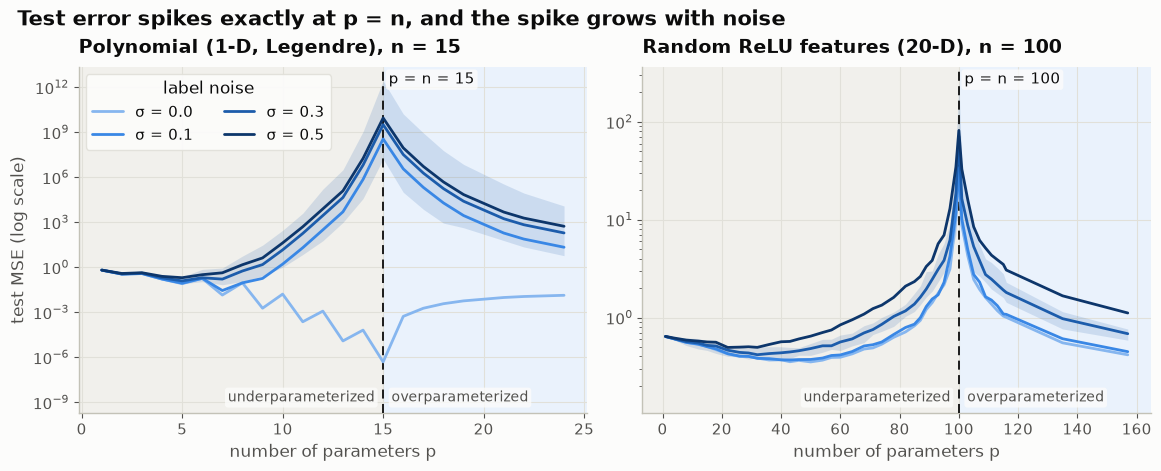

In [2]:
colors = noise_colors(NOISES)
fig, axes = new_figure(ncols=2, width=11.5, height=4.6)
fig_data = {}
for ax, m, x_max in zip(axes, N, [1.6, 1.6]):
    n = N[m]
    fig_data[m] = {"n_train": n, "curves": {}}
    for s in NOISES:
        c = agg[m][(agg[m]["noise"] == s) & (agg[m]["n_params"] <= x_max * n)]
        plot_curve(ax, c, colors[s], f"σ = {s}", band=s == SIGMA)
        fig_data[m]["curves"][str(s)] = {"n_params": c["n_params"].tolist(), "median": c["median"].tolist()}
    capacity_axes(ax, n, ylabel="test MSE (log scale)" if m == "polynomial" else "")
    ax.set_title(f"{MODEL_LABELS[m]}, n = {n}")
axes[0].legend(loc="upper left", title="label noise", ncols=2)
fig.suptitle("Test error spikes exactly at p = n, and the spike grows with noise", x=0.01, ha="left")
publish_figure(
    fig, "02_peak_at_threshold", "The interpolation peak",
    "Median test error against model size up to 1.6 n, for four label-noise levels (lighter = less noise). "
    f"Band: interquartile range at σ = {SIGMA}. Dashed line: the interpolation threshold p = n.",
    fig_data,
)
peak_table = pd.DataFrame(
    {
        f"{m} σ={s}": {
            "peak at p": summaries[(m, s)].peak_params,
            "median test MSE at peak": summaries[(m, s)].peak_error,
            "sweet-spot MSE": summaries[(m, s)].classical_min_error,
            "peak / sweet spot": summaries[(m, s)].peak_over_classical,
        }
        for m in N for s in NOISES
    }
).T
peak_table

Two things to read off the table and the figure:

1. **Location.** With noise, the maximum of the median curve is at $p = n$ in every case: degree 14 for 15 points, 100 features for 100 points. It is not random bad luck near some capacity. It is the predictable worst case.
2. **Height.** For the polynomial, the peak is about $3\times10^{9}$ at $\sigma = 0.3$: ten orders of magnitude above the sweet spot. Random features peak about 170× above theirs. Without noise the 1-D peak all but disappears, and it grows steadily with $\sigma$ in both tracks.

## What the worst model looks like

At $p = n$ the least-squares problem is a square linear system with exactly one solution, and that solution must pass through every noisy point.

{'png': '/workspaces/double_descent_101/outputs/figures/02_contorted_fit.png',
 'json': '/workspaces/double_descent_101/outputs/data/02_contorted_fit.json'}

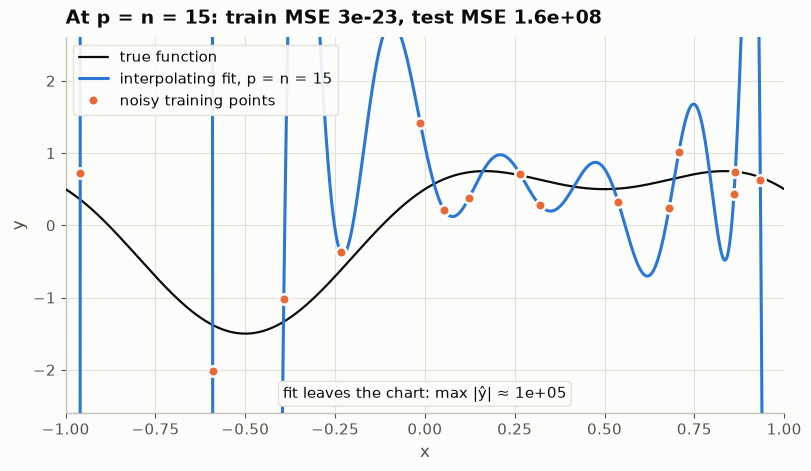

In [3]:
n = N["polynomial"]
ex = example_fits(settings, [n], noise=SIGMA)
fig, (ax,) = new_figure(width=8.0, height=4.6)
plot_fit(ax, ex.x_grid, ex.f_grid, ex.x_train, ex.y_train, ex.predictions[n], label=f"interpolating fit, p = n = {n}")
ax.set_title(f"At p = n = {n}: train MSE {ex.train_mse[n]:.0e}, test MSE {format_error(ex.test_mse[n])}")
ax.legend(loc="upper left", fontsize=10.5)
publish_figure(
    fig, "02_contorted_fit", "The contorted interpolant",
    f"One draw of {n} noisy points (σ = {SIGMA}). The degree-{n - 1} polynomial is the unique curve through all of "
    "them; between the points it swings far outside the plotted range.",
    {"noise": SIGMA, "n_params": n, "train_mse": ex.train_mse[n], "test_mse": ex.test_mse[n],
     "max_abs_prediction": float(np.max(np.abs(ex.predictions[n]))),
     "x_train": ex.x_train, "y_train": ex.y_train,
     "x_grid": ex.x_grid[::10], "f_grid": ex.f_grid[::10], "prediction": ex.predictions[n][::10]},
)

## Why the threshold, exactly?

Write the fit as $\hat\theta = \Phi^{+} y$ with $y = f + \sigma\varepsilon$. The noise part of the solution is roughly $\sigma\varepsilon$ divided by the **smallest singular value** $s_{\min}$ of the design matrix $\Phi$ (shape $n \times p$):

- **$p < n$ (tall $\Phi$):** least squares cannot fit $n$ points with fewer parameters, so it averages the noise away. $s_{\min}$ is comfortably large.
- **$p = n$ (square $\Phi$):** a random square matrix is almost always nearly singular. $s_{\min}$ collapses, so the noise is amplified enormously, and so are the coefficients.
- **$p > n$ (wide $\Phi$):** every extra column raises $s_{\min}$ again, so interpolating no longer needs huge coefficients.

The random-feature track, measured across the whole capacity range:

median s_min: p≈n/2 0.669, p=n 0.0119, p≈2n 0.949


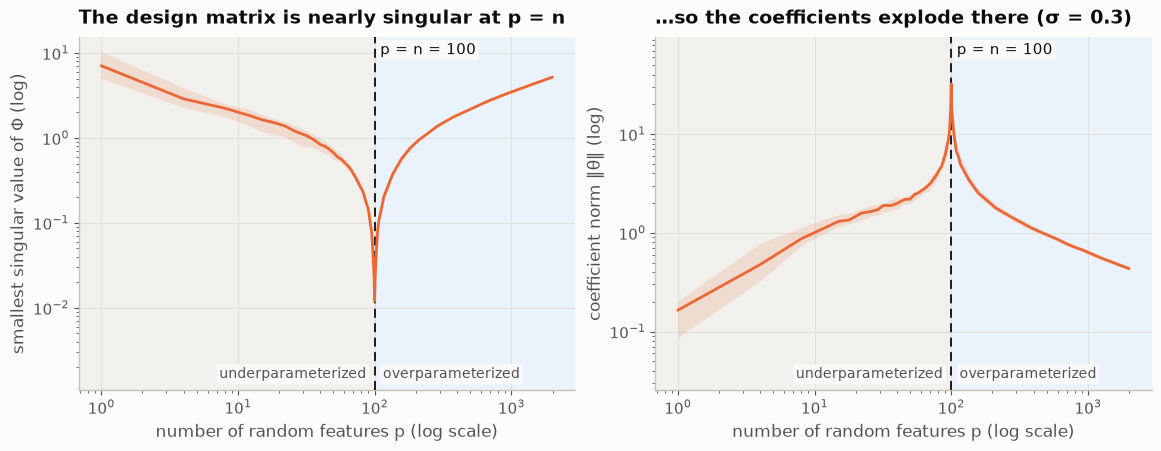

In [4]:
m = "random_features"
n = N[m]
cond = conditioning_sweep(factory_for(m, settings), task_for(m, settings), n_train=n,
                          n_params_grid=sorted(agg[m]["n_params"].unique()),
                          n_seeds=settings.random_features.n_seeds, seed=settings.seed)
smin = aggregate(cond.assign(model=m, n_train=n, noise=0.0), value="sigma_min")
norms = aggregate(sweeps[m][sweeps[m]["noise"] == SIGMA], value="coef_norm")

fig, axes = new_figure(ncols=2, width=11.5, height=4.4)
plot_curve(axes[0], smin, MODEL_COLORS[m], None)
capacity_axes(axes[0], n, ylabel="smallest singular value of Φ (log)", logx=True)
axes[0].set_title("The design matrix is nearly singular at p = n")
plot_curve(axes[1], norms, MODEL_COLORS[m], None)
capacity_axes(axes[1], n, ylabel="coefficient norm ‖θ‖ (log)", logx=True)
axes[1].set_title(f"…so the coefficients explode there (σ = {SIGMA})")
for ax in axes:
    ax.set_xlabel("number of random features p (log scale)")
publish_figure(
    fig, "02_why_it_spikes", "Why the peak sits at p = n",
    f"Random-feature track, n = {n}. Left: median smallest singular value of the training design matrix. "
    f"Right: median norm of the min-norm coefficients at σ = {SIGMA}. Bands: interquartile range.",
    {"n_train": n, "noise": SIGMA, "n_params": smin["n_params"].tolist(),
     "sigma_min_median": smin["median"].tolist(), "coef_norm_median": norms["median"].tolist()},
)
s_at = smin.set_index("n_params")["median"]
near = lambda p: float(s_at.iloc[int(np.abs(s_at.index.to_numpy() - p).argmin())])
print(f"median s_min: p≈n/2 {near(n / 2):.3f}, p=n {near(n):.4f}, p≈2n {near(2 * n):.3f}")

## What you just saw

- **The peak is at $p = n$, not "somewhere big".** Both tracks, every noisy setting: the worst model has exactly as many parameters as data points.
- **The peak is made of noise.** With $\sigma = 0$ the polynomial barely bumps; at $\sigma = 0.3$ it reaches billions. Interpolating noise through a square, nearly singular system is what contorts the model.
- **Mechanism, not magic.** The smallest singular value of the design matrix collapses at $p = n$ and recovers on both sides; the coefficient norm mirrors it.

If you stopped the sweep here, the lesson would be "more parameters, catastrophically worse". Notebook 03 adds parameters anyway.

In [5]:
save_json(
    {
        "notebook": "02_the_interpolation_peak",
        "claim": "Test error peaks exactly at the interpolation threshold p = n, and the peak grows with label noise.",
        "settings": {"noise_levels": NOISES, "headline_noise": SIGMA, "n_train": N, "seed": settings.seed},
        "results": {
            "peaks": {f"{m}|sigma={s}": summaries[(m, s)].to_dict() for m in N for s in NOISES},
            "contorted_fit": {"n_params": N["polynomial"], "train_mse": ex.train_mse[N["polynomial"]],
                              "test_mse": ex.test_mse[N["polynomial"]]},
            "rf_sigma_min_median": {"half_n": near(n / 2), "n": near(n), "two_n": near(2 * n)},
        },
        "figures": ["02_peak_at_threshold", "02_contorted_fit", "02_why_it_spikes"],
        "takeaways": [
            "With noise, the median test error peaks at p = n in both tracks.",
            "The peak is made of noise: it nearly vanishes at sigma = 0 for the polynomial and grows with sigma.",
            "At p = n the design matrix is nearly singular, so fitted noise and coefficients explode.",
        ],
        "next": "03_the_second_descent",
    },
    "02_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/02_summary.json')